There are 1213 audio clips across nine categories from the kaggle dataset.

**A key practical issue is that:**
Each audio file has a different length.

*   Some clips are short (a few seconds)
*   Others are much longer (up to several seconds more than the short ones)
*   Even within the same class, durations vary.



**Files are stored in different formats, mainly:**
.wav, .ogg and a few other audio extensions.

Because of this, the raw dataset is not uniform:
there is no “one fixed length” input, and there is no guarantee that all files share the same encoding or container type.

Neural networks (and model.fit) expect each example in a batch to have the same shape.
A batch cannot contain both a 3-second waveform and a 9-second waveform; they must be standardized to a common length and representation.
This is why I had to research carefully about preprocessing(around 10 hours) instead of just reading the files and training a model.

In [1]:
!pip install -q librosa

My previous experiments before this final draft involved using different lengths and adding “extra noise” to one class

At first, I was thinking in terms of:
Cry clips that were around 7 seconds
Not-cry clips (laugh, noise, silence) that were mostly around 5 seconds

The naive idea was to extend not-cry clips to 7 seconds by adding 2 seconds of silence or noise at the end.

I also researched about adding special noise only to one class to balance things.
Very quickly I realized If only one class always has a very specific pattern (e.g., “5s audio + 2s silence at the end” or a special noise signature),
the model can cheat by learning that artifact instead of the real baby-cry acoustics.
That’s called a spurious correlation / label leakage: the label is indirectly encoded in the preprocessing.


In [2]:
import librosa
import numpy as np
import tensorflow as tf
from pathlib import Path

SAMPLE_RATE = 16000
TARGET_SEC  = 5
TARGET_LEN  = SAMPLE_RATE * TARGET_SEC   # 5 * 16000 = 80000 samples

In [3]:
def load_wav_5s_16k_focus(filename):

    if isinstance(filename, Path):
        filename = str(filename)

    # 1. Load mono audio at 16 kHz
    y, sr = librosa.load(filename, sr=SAMPLE_RATE, mono=True)

    # Edge case: empty audio
    if len(y) == 0:
        return tf.zeros(TARGET_LEN, dtype=tf.float32)

    # 2. If shorter than 5s → pad to 5s (centered)
    if len(y) <= TARGET_LEN:
        pad_total = TARGET_LEN - len(y)
        pad_left  = pad_total // 2
        pad_right = pad_total - pad_left
        y = np.pad(y, (pad_left, pad_right), mode="constant")
        return tf.convert_to_tensor(y, dtype=tf.float32)

    # 3. If longer than 5s → find loudest region via RMS and crop
    frame_length = 2048
    hop_length   = 512

    rms = librosa.feature.rms(
        y=y,
        frame_length=frame_length,
        hop_length=hop_length
    )[0]   # shape: (n_frames,)

    max_frame = np.argmax(rms)
    center    = max_frame * hop_length   # approx sample index of loudest point

    # 4. Center a 5s window around that point
    start = center - TARGET_LEN // 2
    end   = start + TARGET_LEN

    # Clamp to valid range
    if start < 0:
        start = 0
        end   = TARGET_LEN
    if end > len(y):
        end   = len(y)
        start = end - TARGET_LEN

    y_window = y[start:end]      # exactly TARGET_LEN samples
    return tf.convert_to_tensor(y_window, dtype=tf.float32)


The reason for binary classification is such that I have spent around 10 to 12 hours doing the data pre processing and arriving at the right solution.

So I realised, I wouldn't have enough time to build a good model to do multi-class classification, so started with binary classification of cries vs notcries, making sure I'm able to build a good model.

So I sampled random 324 files, acorss 6 categories of 989 files, to maintain class balance across two classes.

Also the above function load_wav_5s_16k_focus is used to trim the files into 5-s window, with 16,0000 samples per second, which gives us 80,000 sample per datapoint.

In [4]:
import kagglehub
from pathlib import Path

path = kagglehub.dataset_download("mennaahmed23/baby-crying-sounds-dataset")
DATA_DIR = Path(path)

AUDIO_EXTS = {".wav", ".ogg", ".mp3", ".m4a"}

def collect_class_files(class_name):
    return [
        p for p in DATA_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in AUDIO_EXTS
        and p.parent.name.lower() == class_name.lower()
    ]

cry_classes = ["belly pain", "burping", "cold_hot", "discomfort", "hungry", "tired"]
notcry_classes = ["laugh", "noise", "silence"]

# NOT-CRY
laugh_files   = collect_class_files("laugh")
noise_files   = collect_class_files("noise")
silence_files = collect_class_files("silence")

# CRY (multiple classes)
cry_files = []
for c in cry_classes:
    cry_files.extend(collect_class_files(c))

Using Colab cache for faster access to the 'baby-crying-sounds-dataset' dataset.


In [5]:
notcry = laugh_files + noise_files + silence_files
print("NOT-CRY:", len(notcry))
print("CRY:", len(cry_files))

NOT-CRY: 324
CRY: 989


In [6]:
cry = cry_files[:324]
print("Using cry files:", len(cry))

Using cry files: 324


The Librosa library was really helpful for this project, from displaying the audio to helping with mel spectogram.

In [7]:
import librosa.display
import IPython.display as ipd

In [8]:
ipd.Audio(notcry[105])

In [9]:
cry_example    = cry[210]
notcry_example = notcry[1]

cry_wave    = load_wav_5s_16k_focus(cry_example)
notcry_wave = load_wav_5s_16k_focus(notcry_example)

print(cry_example, cry_wave.shape)
print(notcry_example, notcry_wave.shape)


/kaggle/input/baby-crying-sounds-dataset/Baby Crying Sounds/burping/548c.wav (80000,)
/kaggle/input/baby-crying-sounds-dataset/Baby Crying Sounds/laugh/laugh_1.m4a_68.wav (80000,)


In [10]:
import matplotlib.pyplot as plt

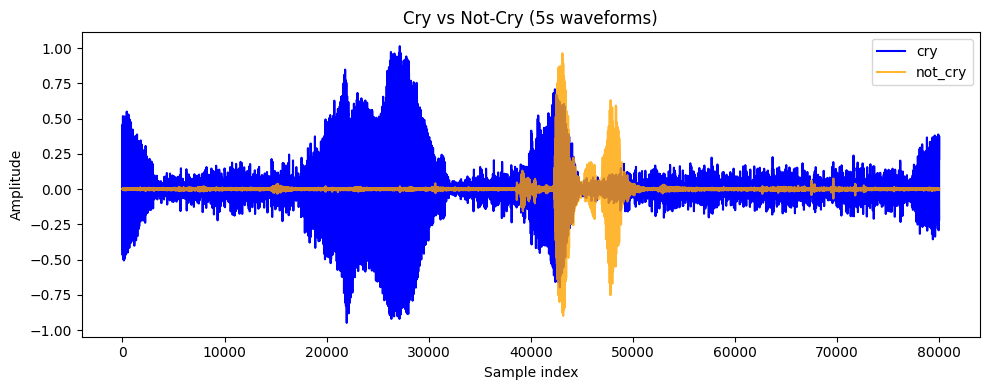

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(cry_wave,    color="blue",   label="cry")
plt.plot(notcry_wave, color="orange", label="not_cry", alpha=0.8)

plt.title("Cry vs Not-Cry (5s waveforms)")
plt.xlabel("Sample index")
plt.ylabel("Amplitude")
plt.legend()
plt.tight_layout()
plt.show()


The above visulatization represents cries vs not cries, this represents the cries have large frequencies, and denser frequency highs.

In [12]:
import numpy as np

CRY_LABEL    = 1
NOTCRY_LABEL = 0

data = []

# Trim all cry files
for p in cry:
    wave = load_wav_5s_16k_focus(p)     # (80000,)
    data.append((wave.numpy(), CRY_LABEL))

# Trim all not-cry files
for p in notcry:
    wave = load_wav_5s_16k_focus(p)     # (80000,)
    data.append((wave.numpy(), NOTCRY_LABEL))

print("Total samples in data:", len(data))

# Optional: shuffle
import random
random.shuffle(data)

# If you want X, y arrays for modeling:
X = np.stack([d[0] for d in data], axis=0)   # (648, 80000)
y = np.array([d[1] for d in data], dtype=np.int64)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("cry    :", (y == 1).sum())
print("notcry :", (y == 0).sum())


Total samples in data: 648
X shape: (648, 80000)
y shape: (648,)
cry    : 324
notcry : 324


The above code, trims all the files make it balanced with each data point as 5s, with 16,000 sample per second, making it 80,000 samples.

Also X and y are numpy arrays with,

*  X = “all the 5-second audio signals”
*  y = “the corresponding cry / not-cry labels”


and I later turned X into X_spec (spectrograms) and trained the CNN using (X_spec, y)


In [13]:
SAMPLE_RATE = 16000

def wave_to_melspec_batch(X, sr=SAMPLE_RATE, n_mels=64, n_fft=1024, hop_length=512):
    """
    X: np.array of shape (N, 80000) – 5s waveforms at 16kHz
    Returns: np.array of shape (N, n_mels, time_frames, 1)
    """
    specs = []
    for wave in X:
        # 1. Mel power spectrogram
        S = librosa.feature.melspectrogram(
            y=wave,
            sr=sr,
            n_fft=n_fft,
            hop_length=hop_length,
            n_mels=n_mels
        )  # (n_mels, time)

        # 2. Convert to log scale (dB)
        S_db = librosa.power_to_db(S, ref=np.max).astype(np.float32)

        # 3. Add channel dimension -> (n_mels, time, 1)
        S_db = np.expand_dims(S_db, axis=-1)
        specs.append(S_db)

    X_spec = np.stack(specs, axis=0)
    return X_spec

X_spec = wave_to_melspec_batch(X)
print("X_spec shape:", X_spec.shape)


X_spec shape: (648, 64, 157, 1)


The wav file is converted to mel spectogram, this is inspired from other research papers and youtube, where people have used mel spectograms.

This actually made sense, as this reduced the number of features form 80,000 to 10,000 making it efficient and smart and also this makes it easier to train a 2d cnn.

In [14]:
idx_cry    = np.where(y == 1)[0][3]  # first cry example
idx_notcry = np.where(y == 0)[0][3]  # first not-cry example

print("cry index    :", idx_cry)
print("not-cry index:", idx_notcry)

cry index    : 3
not-cry index: 14


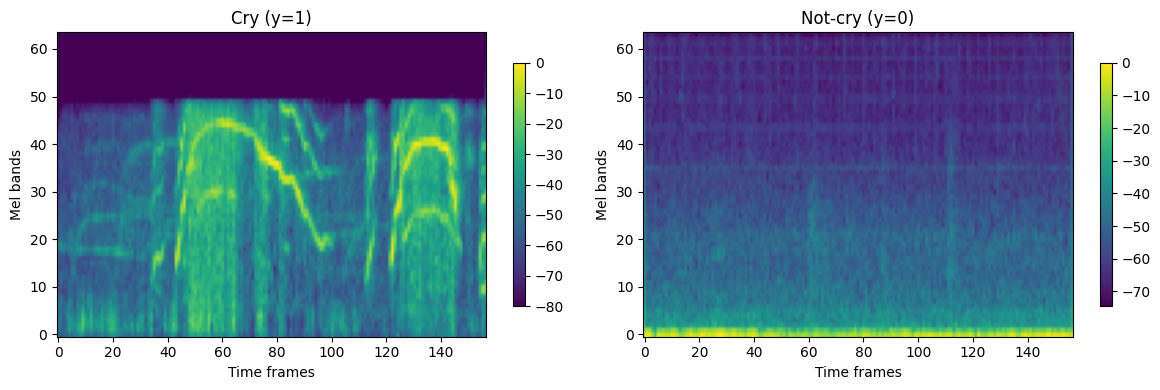

In [15]:
# Remove the channel dim: (64, 157)
spec_cry    = X_spec[idx_cry,    :, :, 0]
spec_notcry = X_spec[idx_notcry, :, :, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Cry
im0 = axes[0].imshow(spec_cry,
                     origin="lower",
                     aspect="auto")
axes[0].set_title(f"Cry (y={y[idx_cry]})")
axes[0].set_xlabel("Time frames")
axes[0].set_ylabel("Mel bands")
fig.colorbar(im0, ax=axes[0], shrink=0.8)

# Not-cry
im1 = axes[1].imshow(spec_notcry,
                     origin="lower",
                     aspect="auto")
axes[1].set_title(f"Not-cry (y={y[idx_notcry]})")
axes[1].set_xlabel("Time frames")
axes[1].set_ylabel("Mel bands")
fig.colorbar(im1, ax=axes[1], shrink=0.8)

plt.tight_layout()
plt.show()


In [16]:
from sklearn.model_selection import train_test_split
import numpy as np

# X_spec: (648, 64, 157, 1)
# y: (648,)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_spec, y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape,   y_val.shape)
print("Test :", X_test.shape,  y_test.shape)


Train: (453, 64, 157, 1) (453,)
Val  : (97, 64, 157, 1) (97,)
Test : (98, 64, 157, 1) (98,)


In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models

input_shape = X_spec.shape[1:]  # (64, 157, 1)

model = models.Sequential([
    layers.Input(shape=input_shape),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPool2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPool2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPool2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")  # binary: cry (1) vs not-cry (0)
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 19, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9728)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       622,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 646,017 (2.46 MB)

 Trainable params: 646,017 (2.46 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=16,
    verbose=1
)


Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step - accuracy: 0.5857 - loss: 2.0522 - val_accuracy: 0.8660 - val_loss: 0.4734
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8217 - loss: 0.4065 - val_accuracy: 0.9691 - val_loss: 0.3155
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8706 - loss: 0.3369 - val_accuracy: 0.9175 - val_loss: 0.1959
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8923 - loss: 0.2578 - val_accuracy: 0.9175 - val_loss: 0.1409
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9018 - loss: 0.2345 - val_accuracy: 0.9381 - val_loss: 0.2323
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9014 - loss: 0.2238 - val_accuracy: 0.9588 - val_loss: 0.1640
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9299 - loss: 0.1721 - val_accuracy: 0.9794 - val_loss: 0.1148
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9654 - loss: 0.1475 - val_accuracy: 0.9794 - val_los

In [19]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss    : {test_loss:.4f}")


Test Accuracy: 0.9286
Test Loss    : 0.3646


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step


<Figure size 400x400 with 0 Axes>

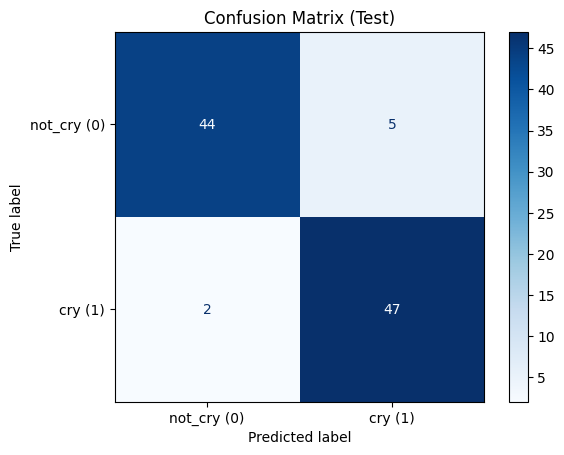

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_proba = model.predict(X_test)
y_pred  = (y_proba >= 0.5).astype(int).ravel()

cm = confusion_matrix(y_test, y_pred, labels=[0,1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["not_cry (0)", "cry (1)"])

plt.figure(figsize=(4,4))
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Test)")
plt.show()

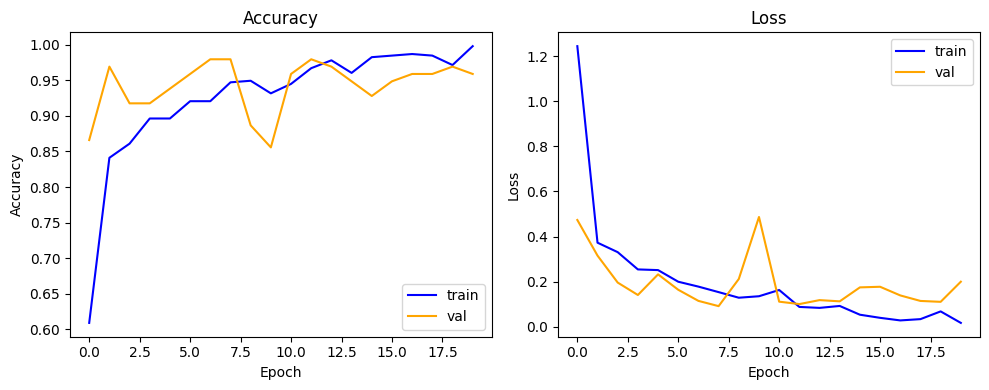

In [21]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="train", color="blue")
plt.plot(history.history["val_accuracy"], label="val",   color="orange")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="train", color="blue")
plt.plot(history.history["val_loss"], label="val",   color="orange")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Misclassified samples: 7


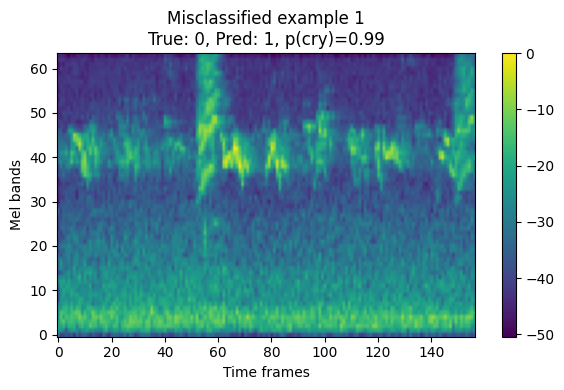

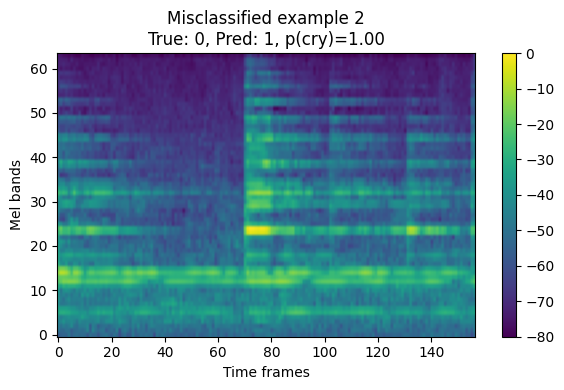

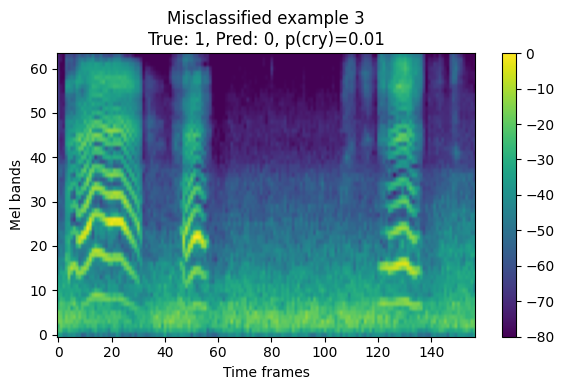

In [22]:
mis_idx = np.where(y_pred != y_test)[0]
print("Misclassified samples:", len(mis_idx))

n_show = min(3, len(mis_idx))  # show up to 3

for k in range(n_show):
    i = mis_idx[k]

    spec = X_test[i, :, :, 0]
    true_label = y_test[i]
    pred_label = y_pred[i]
    prob = y_proba[i][0]

    plt.figure(figsize=(6, 4))
    plt.imshow(spec, origin="lower", aspect="auto")
    plt.title(f"Misclassified example {k+1}\nTrue: {true_label}, Pred: {pred_label}, p(cry)={prob:.2f}")
    plt.xlabel("Time frames")
    plt.ylabel("Mel bands")
    plt.colorbar()
    plt.tight_layout()
    plt.show()



In [23]:
import numpy as np
from pathlib import Path

TARGET_CRY_CLASSES = ["belly pain", "hungry", "laugh", "discomfort"]
cry3_label_map = {name: idx for idx, name in enumerate(TARGET_CRY_CLASSES)}
print("Label map:", cry3_label_map)

AUDIO_EXTS = {".wav", ".ogg", ".mp3", ".m4a"}

def collect_class_files(class_name):
    return [
        p for p in DATA_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower() in AUDIO_EXTS
        and p.parent.name.lower() == class_name.lower()
    ]

N_PER_CLASS = 108
rng = np.random.default_rng(42)  # for reproducibility

paths_3_list = []
labels_3_list = []

for cname in TARGET_CRY_CLASSES:
    cid = cry3_label_map[cname]
    files = np.array(collect_class_files(cname))
    print(f"{cname}: {len(files)} files available")

    if len(files) < N_PER_CLASS:
        raise ValueError(f"Not enough files in class {cname}: {len(files)} found")

    chosen_idx = rng.choice(len(files), size=N_PER_CLASS, replace=False)

    paths_3_list.append(files[chosen_idx])
    labels_3_list.append(np.full(N_PER_CLASS, cid, dtype=np.int64))

paths_3  = np.concatenate(paths_3_list)
labels_3 = np.concatenate(labels_3_list)

print("Balanced dataset size:", paths_3.shape[0])        # should be 324
print("Label counts (0=belly_pain,1=hungry,2=discomfort):",
      np.bincount(labels_3))


Label map: {'belly pain': 0, 'hungry': 1, 'laugh': 2, 'discomfort': 3}
belly pain: 124 files available
hungry: 382 files available
laugh: 108 files available
discomfort: 135 files available
Balanced dataset size: 432
Label counts (0=belly_pain,1=hungry,2=discomfort): [108 108 108 108]


In [26]:
import librosa
import numpy as np

SR = 16000
WIN_SEC = 5.0
N_FFT = 1024
HOP_LENGTH = 512
N_MELS = 64

def load_and_crop_5s(path, sr=SR, win_sec=WIN_SEC):
    """Load audio, resample to sr, and extract a 5s high-energy window."""
    y, sr = librosa.load(str(path), sr=sr, mono=True)
    target_len = int(sr * win_sec)

    # Pad if shorter than 5s
    if len(y) < target_len:
        y = np.pad(y, (0, target_len - len(y)))
        return y

    # If exactly 5s, just return
    if len(y) == target_len:
        return y

    # If longer: energy-based window selection
    frame_length = 1024
    hop = 512
    rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop)[0]

    win_frames = max(1, int(target_len / hop))
    if win_frames >= len(rms):
        # Fallback: center crop
        start = max(0, len(y) // 2 - target_len // 2)
        end = start + target_len
        return y[start:end]

    window_energy = np.convolve(rms, np.ones(win_frames), mode="valid")
    best_start_frame = int(np.argmax(window_energy))
    best_start_sample = best_start_frame * hop
    best_end_sample = best_start_sample + target_len
    if best_end_sample > len(y):
        best_start_sample = len(y) - target_len
        best_end_sample = len(y)
    return y[best_start_sample:best_end_sample]

def waveform_to_logmel(y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    """Convert 1D waveform to normalized log-Mel spectrogram."""
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    S_db = librosa.power_to_db(S, ref=np.max)
    # Optional: scale to [0,1] for nicer training
    S_db = (S_db - S_db.min()) / (S_db.max() - S_db.min() + 1e-8)
    return S_db

def path_to_spec(path):
    """Full pipeline: path -> 5s crop -> log-Mel spec with channel dim."""
    y = load_and_crop_5s(path)
    S_db = waveform_to_logmel(y)
    return S_db[..., np.newaxis].astype(np.float32)


In [27]:
X3_spec = np.stack([path_to_spec(p) for p in paths_3], axis=0)
y3 = labels_3.copy()

print("X3_spec shape:", X3_spec.shape)  # (324, 64, ~157, 1)
print("y3 shape:", y3.shape)
print("Label counts check:", np.bincount(y3))


X3_spec shape: (432, 64, 157, 1)
y3 shape: (432,)
Label counts check: [108 108 108 108]


In [28]:
from sklearn.model_selection import train_test_split

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3_spec, y3,
    test_size=60,
    stratify=y3,
    random_state=42
)

print("Train:", X3_train.shape, y3_train.shape)
print("Test :", X3_test.shape,  y3_test.shape)
print("Train labels:", np.bincount(y3_train))
print("Test labels :", np.bincount(y3_test))



Train: (372, 64, 157, 1) (372,)
Test : (60, 64, 157, 1) (60,)
Train labels: [93 93 93 93]
Test labels : [15 15 15 15]


In [29]:
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras import regularizers

num_classes = len(TARGET_CRY_CLASSES)

inputs = layers.Input(shape=(64, 157, 1), name="cry_input")


x = inputs
for layer in model.layers[:-1]:
    if isinstance(layer, tf.keras.layers.InputLayer):
        continue
    layer.trainable = False
    x = layer(x)

x = layers.Dense(128, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4))(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax",
    name="cry_type_head"
)(x)

tl_model = models.Model(inputs=inputs, outputs=outputs, name="cry_type_model")

tl_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tl_model.summary()




Model: "cry_type_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cry_input (InputLayer)          │ (None, 64, 157, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 19, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9728)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       622,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cry_type_head (Dense)           │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 654,788 (2.50 MB)

 Trainable params: 8,836 (34.52 KB)

 Non-trainable params: 645,952 (2.46 MB)

In [30]:
early_stop_3 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_3 = tl_model.fit(
    X3_train, y3_train,
    validation_split=0.2,    # 20% of 264 (~52) as validation
    epochs=20,
    batch_size=16,
    callbacks=[early_stop_3],
    verbose=1
)


Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 227ms/step - accuracy: 0.2375 - loss: 2.0148 - val_accuracy: 0.2800 - val_loss: 1.4320
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2779 - loss: 1.6491 - val_accuracy: 0.2000 - val_loss: 1.4667
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2420 - loss: 1.5906 - val_accuracy: 0.1867 - val_loss: 1.4075
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2916 - loss: 1.4702 - val_accuracy: 0.2000 - val_loss: 1.4207
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2067 - loss: 1.5584 - val_accuracy: 0.2133 - val_loss: 1.4182
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2724 - loss: 1.5235 - val_accuracy: 0.2000 - val_loss: 1.4036
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2915 - loss: 1.4707 - val_accuracy: 0.2000 - val_loss: 1.3893
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2179 - loss: 1.5135 - val_accuracy: 0.2400 - val_lo

In [31]:
from sklearn.metrics import classification_report, confusion_matrix

test_loss_3, test_acc_3 = tl_model.evaluate(X3_test, y3_test, verbose=0)
print(f"3-class (belly pain / hungry / laugh/ discomfort) test accuracy: {test_acc_3:.4f}")
print(f"Test loss: {test_loss_3:.4f}")

y3_proba = tl_model.predict(X3_test)
y3_pred  = np.argmax(y3_proba, axis=1)

print("\nClassification report:")
print(classification_report(
    y3_test,
    y3_pred,
    target_names=TARGET_CRY_CLASSES
))



3-class (belly pain / hungry / laugh/ discomfort) test accuracy: 0.2500
Test loss: 1.3396
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 344ms/step

Classification report:
              precision    recall  f1-score   support

  belly pain       0.00      0.00      0.00        15
      hungry       0.00      0.00      0.00        15
       laugh       0.00      0.00      0.00        15
  discomfort       0.25      1.00      0.40        15

    accuracy                           0.25        60
   macro avg       0.06      0.25      0.10        60
weighted avg       0.06      0.25      0.10        60



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


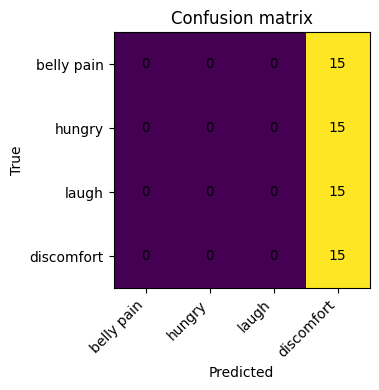

In [32]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(y3_test, y3_pred)
labels = ["belly pain", "hungry", "laugh", "discomfort"]

fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(cm)  # just raw counts

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix")

# put counts in each cell
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class_names = ["belly pain", "hungry", "laugh", "discomfort"]

for c, cname in enumerate(class_names):
    mis_idx = np.where((y3_test == c) & (y3_pred != c))[0]

    if len(mis_idx) == 0:
        print(f"No misclassified examples for class: {cname}")
        continue

    idx = mis_idx[0]   # take the first misclassified example
    spec = X3_test[idx, :, :, 0]  # (64, 157)

    plt.figure(figsize=(5, 4))
    plt.imshow(spec, origin="lower", aspect="auto")
    plt.title(
        f"Misclassified example\nTrue: {cname}, "
        f"Pred: {class_names[y3_pred[idx]]}"
    )
    plt.xlabel("Time frames")
    plt.ylabel("Mel bands")
    plt.colorbar()
    plt.tight_layout()
    plt.show()
